# 🔑 Reference Solution · Practical Assignment

> Open this only after attempting the assignment. There are many valid approaches: the goal is a *fair, leak-free comparison* and *honest conclusions*.

# Lesson 8 · Practical Assignment: An Agricultural Price Forecasting Experiment
**Phase 7: Time-Series Analysis & Forecasting** &nbsp;|&nbsp; **Week 15** &nbsp;|&nbsp; ⏱ ≈ 240 minutes

> 🎯 **By the end of this lesson you will be able to:**
    > - Carry out a complete, honest forecasting experiment on historical agricultural market prices
> - Combine visualisation, decomposition, baselines, ARIMA/SARIMAX, lag-feature regression, Random Forest and XGBoost
> - Compare all models fairly with one **walk-forward protocol**, baselines and skill scores
> - Communicate a recommendation, including limitations

**Prerequisites:** Lessons 0–7.

**How to work through this notebook:** read a section, *predict* what the next cell will show, run it, and compare.
Prediction before execution is the fastest way to build intuition. Problems come with progressive hints (open them one at a time:
struggling a little is where learning happens). Reference solutions live in `solutions/`.

## 🌾 The scenario

You have just joined the analytics team of an agricultural marketing board. Traders, farmers' cooperatives and the ministry all ask the same thing:
**"What will the wholesale price be in 1, 4 and 8 weeks: and can we trust your number?"**

Your job: build and *honestly evaluate* a forecasting system for weekly wholesale prices, following the eight steps below.
This notebook is the **guided assignment**: each step has instructions, hints and a **YOUR TURN** cell. The reference solution is in `solutions/08_Practical_Assignment_SOLUTION.ipynb`: open it only after you've tried!

| Step | Task | Lesson to revisit |
|---|---|---|
| 1 | Historical price visualisation | 0, 1 |
| 2 | Trend and seasonality analysis | 1 |
| 3 | Moving-average baseline (+ naive baselines) | 3, 4 |
| 4 | ARIMA or SARIMA(X) | 5 |
| 5 | Regression with lag features | 2, 6 |
| 6 | Random Forest | 6 |
| 7 | XGBoost | 6 |
| 8 | Model comparison and recommendation | 3 |

### The ground rules (the "contract")
1. **Chronological order only.** Never shuffle. Features at time *t* use information from time ≤ *t − h* only.
2. **One protocol for every model:** walk-forward evaluation, `INITIAL = 470` weeks of first training data, a new forecast origin every `STEP = 8` weeks, horizons **1, 4 and 8 weeks**, expanding window, refit at every origin.
3. **Every result goes into the `results` dictionary** via `record(name, walk_forward_table)` so Step 8 can compare them automatically.
4. **Beat the baselines or say honestly that you didn't.**

> 💡 **Tip:** each YOUR-TURN cell starts with placeholders (`None`). The notebook runs top to bottom at any time; the comparison table simply fills up as you complete the steps.

In [1]:
import sys; sys.path.append("..")            # lets us import course_utils.py from the parent folder
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.tools.sm_exceptions         # (imported first: statsmodels registers its own warning filters on import)
import warnings; warnings.filterwarnings("ignore")   # keep the notebook readable; in real projects READ your warnings!
from course_utils import *                    # data loaders, metrics, plotting helpers, check()

## ⚙️ Setup (provided: read it, then run it)
Change `COMMODITY` to `"tomato"`, `"onion"` or `"rice"` to repeat the whole experiment on another market (a great extension: do they rank the same?).

In [2]:
COMMODITY = "maize"                 # try: "tomato", "onion", "rice"
df = load_weekly(COMMODITY)         # weekly data with price, arrivals, rainfall, temp, fuel, festival flag
y = df["price"]

HORIZONS, INITIAL, STEP = (1, 4, 8), 470, 8
results = {}                        # model name -> tidy walk-forward table (origin, target_date, h, actual, forecast)

def record(name, wf):
    """Store a walk-forward result (keeping only the evaluation horizons)."""
    results[name] = wf[wf["h"].isin(HORIZONS)].reset_index(drop=True)
    d = results[name]
    print(f"recorded '{name}': {d['origin'].nunique()} origins | MAE overall = {mae(d.actual, d.forecast):.2f}")

def scoreboard(results):
    """MAE per horizon, overall RMSE, and skill relative to the naive forecast."""
    if not results:
        print("No results recorded yet; complete Steps 3-7 first."); return None
    rows = {}
    for name, w in results.items():
        r = {f"MAE h={h}": mae(w[w.h == h].actual, w[w.h == h].forecast) for h in HORIZONS}
        r["MAE all"], r["RMSE all"] = mae(w.actual, w.forecast), rmse(w.actual, w.forecast)
        rows[name] = r
    t = pd.DataFrame(rows).T
    if "naive" in t.index:
        t["skill (RMSE)"] = 1 - t["RMSE all"] / t.loc["naive", "RMSE all"]
    return t.sort_values("RMSE all").round(3)

print(f"{COMMODITY}: {len(df)} weeks, {df.index[0].date()} → {df.index[-1].date()}")
print(f"Evaluation: first forecast origin after week {INITIAL}  →  {(len(df) - max(HORIZONS) - INITIAL) // STEP + 1} origins × horizons {HORIZONS}")

maize: 626 weeks, 2013-01-06 → 2024-12-29
Evaluation: first forecast origin after week 470  →  19 origins × horizons (1, 4, 8)


## Step 1 · Historical price visualisation

*"Never model what you haven't looked at."* Produce **four** pictures:

| | Plot | What to look for |
|---|---|---|
| 1a | Price over time with a 52-week rolling mean and a ±1 rolling-std band | trend, changing volatility, shocks |
| 1b | **Seasonal plot**: one line per year against week-of-year | is the yearly shape stable? |
| 1c | Price and rainfall together (two y-axes) | does rain lead price? by how long? |
| 1d | Histogram of **weekly log returns** | typical move size, fat tails |

**Then write three observations** in the markdown cell below the plots (a sentence each).

<details><summary>💡 Hint 1</summary>

1a: `y.rolling(52).mean()` and `y.rolling(52).std()`; `ax.fill_between(x, mean - std, mean + std, alpha=.2)`.

</details>

<details><summary>💡 Hint 2</summary>

1b: `pd.DataFrame({'price': y, 'week': y.index.isocalendar().week, 'year': y.index.year}).pivot_table(index='week', columns='year', values='price')` then `.plot(colormap='viridis')`.

</details>

<details><summary>💡 Hint 3</summary>

1c: `ax2 = ax.twinx()`; rainfall is noisy: plot `df['rainfall_mm'].rolling(6).mean()`.

</details>

<details><summary>💡 Hint 4</summary>

1d: `np.log(y).diff().dropna().hist(bins=40)`.

</details>

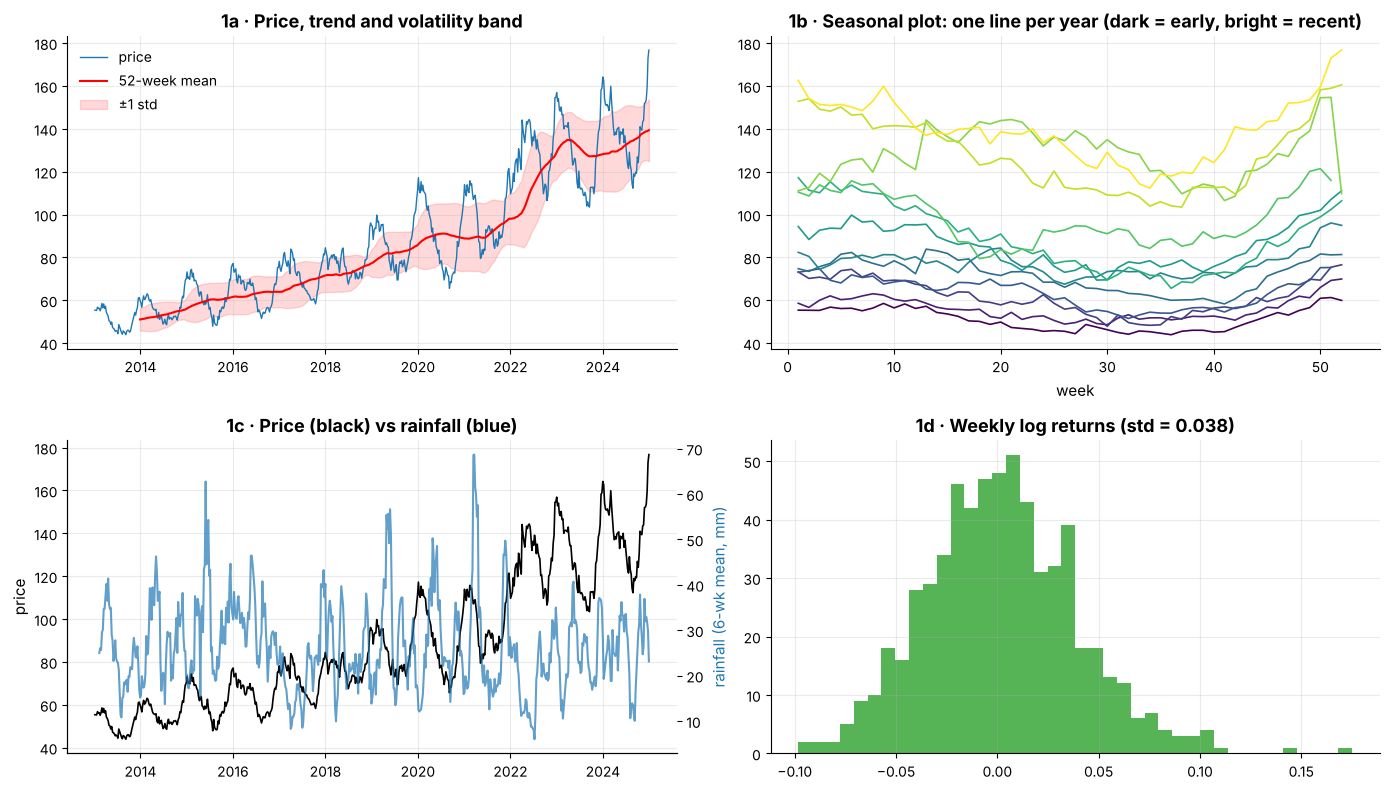

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
# 1a trend + volatility band
m52, s52 = y.rolling(52).mean(), y.rolling(52).std()
axes[0, 0].plot(y, lw=1, label="price"); axes[0, 0].plot(m52, color="red", label="52-week mean")
axes[0, 0].fill_between(y.index, m52 - s52, m52 + s52, color="red", alpha=.15, label="±1 std")
axes[0, 0].set_title("1a · Price, trend and volatility band"); axes[0, 0].legend()
# 1b seasonal plot
sp = pd.DataFrame({"price": y, "week": y.index.isocalendar().week.values, "year": y.index.year}).pivot_table(index="week", columns="year", values="price")
sp.plot(ax=axes[0, 1], colormap="viridis", lw=1.2, legend=False); axes[0, 1].set_title("1b · Seasonal plot: one line per year (dark = early, bright = recent)")
# 1c price vs rainfall
ax = axes[1, 0]; ax.plot(y, color="black", lw=1.2); ax.set_ylabel("price")
ax2 = ax.twinx(); ax2.plot(df["rainfall_mm"].rolling(6).mean(), color="tab:blue", alpha=.7); ax2.set_ylabel("rainfall (6-wk mean, mm)", color="tab:blue"); ax2.grid(False)
ax.set_title("1c · Price (black) vs rainfall (blue)")
# 1d returns
ret = np.log(y).diff().dropna(); axes[1, 1].hist(ret, bins=40, color="tab:green", alpha=.8)
axes[1, 1].set_title(f"1d · Weekly log returns (std = {ret.std():.3f})")
plt.tight_layout(); plt.show()

✍️ **Reference observations** (for maize; yours may differ for other crops):
1. A strong **upward trend** (prices roughly tripled over the 12 years) and a visible **yearly wave**; the seasonal plot shows the same shape repeating each year, shifted upward.
2. **Shocks:** the price rises in 2017 and especially 2022 stand out. Rainfall in the preceding months is much lower: consistent with **drought effects that arrive a couple of months later**.
3. Weekly returns are roughly bell-shaped, centred slightly above zero, with a few larger moves (fat tails ⇒ use robust metrics and don't trust Gaussian intervals blindly).

## Step 2 · Trend and seasonality analysis

Quantify what you saw. Tasks:

1. **STL decomposition** of the *log* price (`period=52`, `robust=True`). Compute the **seasonal strength** and **trend strength** (Lesson 1 formula).
2. Which calendar **months** are above/below trend (in %)? Put the answer in `peak_month` (most expensive) and `trough_month` (cheapest).
3. **Stationarity:** run ADF and KPSS on (i) the price, (ii) log price, (iii) weekly log change, (iv) 52-week seasonal difference of the log price.
4. Plot **ACF and PACF** of the weekly log change. Decide: how many regular differences *d* will your ARIMA need? Store it in `d_needed`.

<details><summary>💡 Hint 1</summary>

`stl = STL(np.log(y), period=52, robust=True).fit()` → `stl.seasonal`, `stl.trend`, `stl.resid`.

</details>

<details><summary>💡 Hint 2</summary>

Strength: `max(0, 1 - resid.var() / (seasonal + resid).var())`; for trend replace seasonal by trend.

</details>

<details><summary>💡 Hint 3</summary>

Month profile: `(np.exp(stl.seasonal).groupby(stl.seasonal.index.month).mean() - 1) * 100`; `idxmax()` / `idxmin()`.

</details>

<details><summary>💡 Hint 4</summary>

ADF/KPSS: `from statsmodels.tsa.stattools import adfuller, kpss`; remember the opposite null hypotheses. Wrap `kpss` in `warnings.catch_warnings()`.

</details>

2.1 seasonal strength = 0.76 | trend strength = 0.96


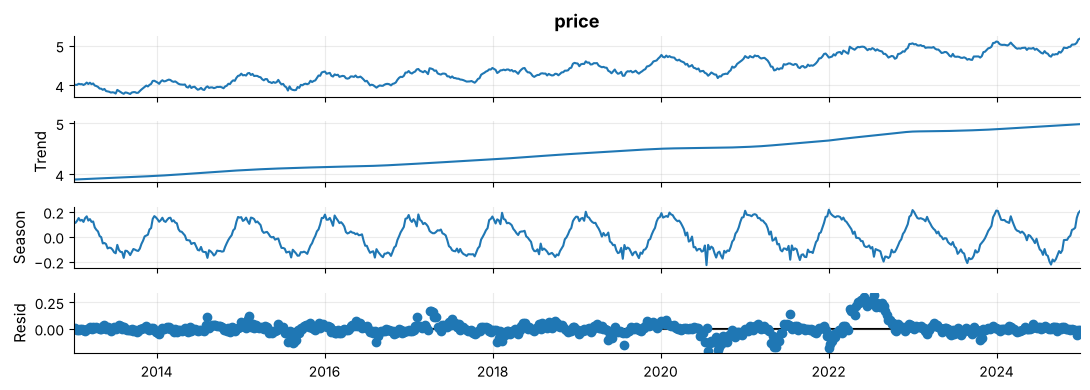

2.2 most expensive month: 1 (+16.6% vs trend) | cheapest month: 9 (-13.6%)


2.3 stationarity tests (ADF wants p<0.05; KPSS wants p>0.05)


,series,ADF_p,KPSS_p
0,price,0.692,0.01
1,log price,0.459,0.01
2,weekly log change,0.000,0.10
3,52-wk seasonal diff of log,0.000,0.10


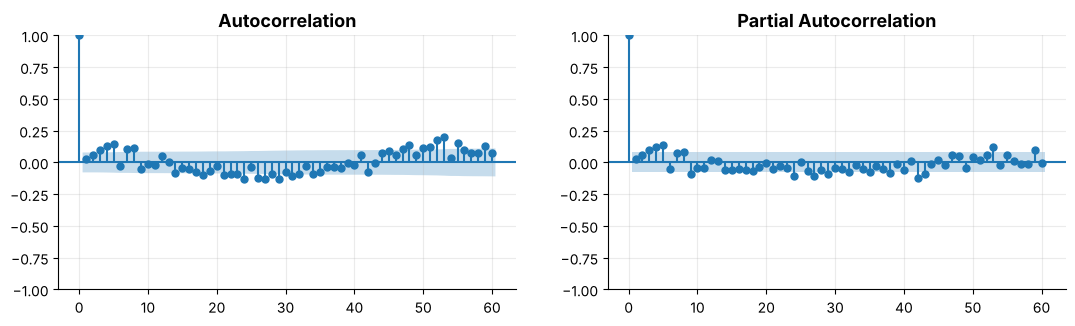

peak month: 1 | trough month: 9 | d needed: 1


In [4]:
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import warnings

ly = np.log(y)
stl = STL(ly, period=52, robust=True).fit()
Fs = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
Ft = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
print(f"2.1 seasonal strength = {Fs:.2f} | trend strength = {Ft:.2f}")
stl.plot(); plt.show()

prof = (np.exp(stl.seasonal).groupby(stl.seasonal.index.month).mean() - 1) * 100
peak_month, trough_month = int(prof.idxmax()), int(prof.idxmin())
print(f"2.2 most expensive month: {peak_month} ({prof.max():+.1f}% vs trend) | cheapest month: {trough_month} ({prof.min():+.1f}%)")

rows = []
for name, x in {"price": y, "log price": ly, "weekly log change": ly.diff(), "52-wk seasonal diff of log": ly.diff(52)}.items():
    x = x.dropna()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore"); kp = kpss(x, regression="c", nlags="auto")[1]
    rows.append(dict(series=name, ADF_p=adfuller(x)[1], KPSS_p=kp))
print("2.3 stationarity tests (ADF wants p<0.05; KPSS wants p>0.05)"); display(pd.DataFrame(rows).round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.3))
plot_acf(ly.diff().dropna(), lags=60, ax=ax[0]); plot_pacf(ly.diff().dropna(), lags=60, ax=ax[1], method="ywm"); plt.show()
d_needed = 1 if adfuller(ly)[1] > 0.05 else 0
print("peak month:", peak_month, "| trough month:", trough_month, "| d needed:", d_needed)

✍️ **Reference conclusions (maize).** Both seasonal and trend strength are high (≈ 0.8 and ≈ 0.95). Maize is cheapest around **August–September** (post-harvest) and dearest in **January–February**. The level and log price fail stationarity tests; the weekly log change passes both, so **d = 1**. The ACF/PACF of the *changes* show only small, scattered spikes (the remaining structure is seasonal, not short-memory ARMA), so we should handle the season with **Fourier terms / seasonal features** rather than a large ARMA part.

## Step 3 · Moving-average baseline (and friends)

Before anything fancy, set the **bar to beat**. Using `walk_forward(y, forecaster, initial=INITIAL, horizon=8, step=STEP)`:

1. `wf_naive`: repeat the last value (`fc_naive`) → `record("naive", wf_naive)`
2. `wf_snaive`: repeat last year (`fc_snaive`)  → `record("seasonal naive", wf_snaive)`
3. `wf_ma`: moving average of **your chosen window** (`fc_ma(train, h, w)`) → `record("moving average", wf_ma)`.
   Try windows 2, 4, 8, 13 on the first few origins (or all of them) and pick one **using the data, not intuition**.

**Question:** which baseline is hardest to beat at h = 1? at h = 8? why?

<details><summary>💡 Hint 1</summary>

`walk_forward(y, fc_naive, initial=INITIAL, horizon=8, step=STEP)` returns a table for h = 1…8; `record` keeps h ∈ {1, 4, 8}.

</details>

<details><summary>💡 Hint 2</summary>

A window loop: `for w in (2, 4, 8, 13): wf = walk_forward(y, lambda tr, h, w=w: fc_ma(tr, h, w), ...)` and compare `mae(wf.actual, wf.forecast)`.

</details>

<details><summary>💡 Hint 3</summary>

Remember the closure trap: write `w=w` in the lambda.

</details>

In [5]:
wf_naive = walk_forward(y, fc_naive, initial=INITIAL, horizon=8, step=STEP)
wf_snaive = walk_forward(y, fc_snaive, initial=INITIAL, horizon=8, step=STEP)

ma_scores = {}
for w in (2, 4, 8, 13):
    wf_w = walk_forward(y, lambda tr, h, w=w: fc_ma(tr, h, w), initial=INITIAL, horizon=8, step=STEP)
    ma_scores[w] = mae(wf_w.actual, wf_w.forecast)
print("MA window → MAE:", {k: round(v, 2) for k, v in ma_scores.items()})
best_w = min(ma_scores, key=ma_scores.get)
wf_ma = walk_forward(y, lambda tr, h: fc_ma(tr, h, best_w), initial=INITIAL, horizon=8, step=STEP)

record("naive", wf_naive); record("seasonal naive", wf_snaive); record(f"moving average ({best_w})", wf_ma)

MA window → MAE: {2: np.float64(9.74), 4: np.float64(10.35), 8: np.float64(12.65), 13: np.float64(14.7)}
recorded 'naive': 19 origins | MAE overall = 8.70
recorded 'seasonal naive': 19 origins | MAE overall = 18.46
recorded 'moving average (2)': 19 origins | MAE overall = 8.79


✍️ **Reference answer.** At h = 1 the *naive* forecast is nearly unbeatable (and short moving averages tie with it) because a price is almost a random walk at the weekly scale. A longer moving average always **lags** the trending price, so the shortest window wins. At longer horizons every flat forecast accumulates the same error from the trend and season it ignores: the room for improvement appears exactly where models capture *structure*.

## Step 4 · ARIMA or SARIMA(X)

Build a statistical forecaster on **log price** (Lesson 5):

1. Choose the ARMA orders: fit `ARIMA(p, 1, q)` for p, q ∈ {0, 1} on the log price and pick the lowest AIC (store in `best_order`).
2. Use the helper `sarimax_forecaster(df, cols, order)` to create forecasters for **three** model variants and record each:
   - `"ARIMA"`: no exogenous columns
   - `"ARIMAX + Fourier"`: the six Fourier columns `sin1…cos3`
   - `"ARIMAX + Fourier + drivers"`: Fourier + `rain6_l8`, `fuel_l8`, `fest`
3. **Diagnose** the third model on the full sample: Ljung–Box test on the residuals; inspect the estimated coefficients (do their signs make sense?).

> ⚠️ Weekly SARIMA with m = 52 is impractical (Lesson 5); Fourier terms *are* the seasonal part. (**Bonus challenge:** resample to monthly and fit a true SARIMA(p,d,q)(P,D,Q)₁₂.)

<details><summary>💡 Hint 1</summary>

`from statsmodels.tsa.arima.model import ARIMA` ; `ARIMA(np.log(y), order=(p, 1, q)).fit().aic`.

</details>

<details><summary>💡 Hint 2</summary>

`cols_f = ['sin1','cos1','sin2','cos2','sin3','cos3']`; `f = sarimax_forecaster(df, cols_f, order=best_order)`; `walk_forward(y, f, initial=INITIAL, horizon=8, step=STEP)`.

</details>

<details><summary>💡 Hint 3</summary>

Each ARIMAX walk-forward takes ~5–15 seconds. For diagnostics: `SARIMAX(...).fit()`, `res.resid`, `acorr_ljungbox(res.resid[1:], lags=[10, 26])`, `res.params`.

</details>

In [6]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

ly = np.log(y)
aics = {(p, q): ARIMA(ly, order=(p, 1, q)).fit().aic for p in range(2) for q in range(2)}
print("AIC:", {k: round(v, 1) for k, v in aics.items()})
best_order = (min(aics, key=aics.get)[0], 1, min(aics, key=aics.get)[1])
print("best order:", best_order)

cols_f = ["sin1", "cos1", "sin2", "cos2", "sin3", "cos3"]
cols_all = cols_f + ["rain6_l8", "fuel_l8", "fest"]
wf_arima = walk_forward(y, sarimax_forecaster(df, [], order=best_order), initial=INITIAL, horizon=8, step=STEP)
wf_arimax_f = walk_forward(y, sarimax_forecaster(df, cols_f, order=best_order), initial=INITIAL, horizon=8, step=STEP)
wf_arimax_all = walk_forward(y, sarimax_forecaster(df, cols_all, order=best_order), initial=INITIAL, horizon=8, step=STEP)

# diagnostics on the full-sample fit of the richest model
X = build_exog(df); valid = X.dropna().index
res = SARIMAX(ly.loc[valid], exog=X.loc[valid, cols_all], order=best_order, trend="n").fit(disp=False)
print("\nLjung-Box on residuals (small p => leftover autocorrelation):"); display(acorr_ljungbox(res.resid[1:], lags=[10, 26]).round(3))
print("Driver coefficients (log-price effect):"); display(res.params[["rain6_l8", "fuel_l8", "fest"]].round(3))

record("ARIMA", wf_arima); record("ARIMAX + Fourier", wf_arimax_f); record("ARIMAX + Fourier + drivers", wf_arimax_all)

AIC: {(0, 0): np.float64(-2327.9), (0, 1): np.float64(-2326.3), (1, 0): np.float64(-2326.3), (1, 1): np.float64(-2336.7)}
best order: (1, 1, 1)



Ljung-Box on residuals (small p => leftover autocorrelation):


,lb_stat,lb_pvalue
10,12.579,0.248
26,31.592,0.207


Driver coefficients (log-price effect):


rain6_l8   -0.130
fuel_l8     0.164
fest        0.045
dtype: float64

recorded 'ARIMA': 19 origins | MAE overall = 8.65
recorded 'ARIMAX + Fourier': 19 origins | MAE overall = 5.79
recorded 'ARIMAX + Fourier + drivers': 19 origins | MAE overall = 4.59


✍️ **Reference answer.** Plain ARIMA ≈ naive (differencing already captures the random-walk part). The **Fourier seasonal terms** give the first big gain and the **lagged rain / fuel / festival drivers** a second one. Signs make sense: more rain 8 weeks ago → lower price (better harvest), higher fuel → higher price, festival weeks → a few percent premium. The Ljung–Box p-values (≈ 0.2) are well above 0.05, so the residuals of the richest model look like white noise: no obvious structure is left for the ARMA part to capture.

## Step 5 · Regression with lag features

Time to treat forecasting as supervised learning (Lesson 6). Use `walk_forward_ml(df, model_factory, horizons=HORIZONS, initial=INITIAL, step=STEP)`:

1. Build a **Ridge regression** pipeline: `make_pipeline(StandardScaler(), Ridge(alpha=10))`. Record as `"Ridge (lag features)"`.
2. **Ablation:** repeat *without* the driver features (`use_drivers=False`) and record as `"Ridge (no drivers)"`. What do the drivers contribute?
3. Fit one Ridge on all data for h = 4 (`make_ml_table(df, 4)`), print the **largest coefficients** (standardised features): what is the model relying on?

> ⚠️ Remember: the table's target is the **h-step log return**; `walk_forward_ml` converts back to prices for you.

<details><summary>💡 Hint 1</summary>

`from sklearn.linear_model import Ridge; from sklearn.pipeline import make_pipeline; from sklearn.preprocessing import StandardScaler`.

</details>

<details><summary>💡 Hint 2</summary>

`walk_forward_ml(df, lambda: make_pipeline(StandardScaler(), Ridge(alpha=10)), horizons=HORIZONS, initial=INITIAL, step=STEP, use_drivers=False)`: extra keyword arguments go to `make_ml_table`.

</details>

<details><summary>💡 Hint 3</summary>

Coefficients: fit on `Xd = X.dropna()`, then `pipe[-1].coef_` aligned with `X.columns`; sort by absolute value.

</details>

In [7]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ridge = lambda: make_pipeline(StandardScaler(), Ridge(alpha=10))
wf_ridge = walk_forward_ml(df, ridge, horizons=HORIZONS, initial=INITIAL, step=STEP)
wf_ridge_nd = walk_forward_ml(df, ridge, horizons=HORIZONS, initial=INITIAL, step=STEP, use_drivers=False)

X4, y4 = make_ml_table(df, 4); ok = X4.notna().all(axis=1) & y4.notna()
pipe = ridge().fit(X4[ok], y4[ok])
coef = pd.Series(pipe[-1].coef_, index=X4.columns).sort_values(key=np.abs, ascending=False)
print("Largest standardised coefficients (h = 4):"); display(coef.head(8).round(4))

record("Ridge (lag features)", wf_ridge); record("Ridge (no drivers)", wf_ridge_nd)

Largest standardised coefficients (h = 4):


cos1        0.0617
rain6_l8   -0.0295
cos2        0.0267
ret_52w    -0.0153
sin2       -0.0152
ret_26w    -0.0143
vol_13      0.0142
fest        0.0120
dtype: float64

recorded 'Ridge (lag features)': 19 origins | MAE overall = 5.76
recorded 'Ridge (no drivers)': 19 origins | MAE overall = 5.93


✍️ **Reference answer.** A *linear* model on well-chosen, scale-free features is already a strong forecaster at h = 4–8 (roughly 35–45 % lower MAE than naive). Removing the driver features raises the overall MAE only modestly (≈ 5.8 → 5.9) and not uniformly across horizons (at h = 8 the no-driver version is even slightly better), with 19 origins that is within noise, so do not over-claim. The largest standardised coefficients are the first seasonal harmonic (`cos1`) and lagged rainfall (`rain6_l8`, negative: more rain → lower prices later).

## Step 6 · Random Forest

Now a non-linear learner. Record `"Random Forest"` using
`RandomForestRegressor(200, min_samples_leaf=5, max_features=0.5, random_state=0, n_jobs=1)` and `walk_forward_ml`.

**Think first:** why do we feed the forest *returns* rather than prices? (Hint: Lesson 6, §2.) Then look at **permutation importance** on a chronological hold-out (train on the first 80 % of rows for h = 4, test on the last 20 %).

<details><summary>💡 Hint 1</summary>

Wrap the constructor in a lambda: `lambda: RandomForestRegressor(200, min_samples_leaf=5, max_features=0.5, random_state=0, n_jobs=1)`.

</details>

<details><summary>💡 Hint 2</summary>

`from sklearn.inspection import permutation_importance`; `permutation_importance(model, Xte, yte, n_repeats=10, random_state=0, scoring='neg_mean_absolute_error')`.

</details>

<details><summary>💡 Hint 3</summary>

This cell takes ~20 s.

</details>

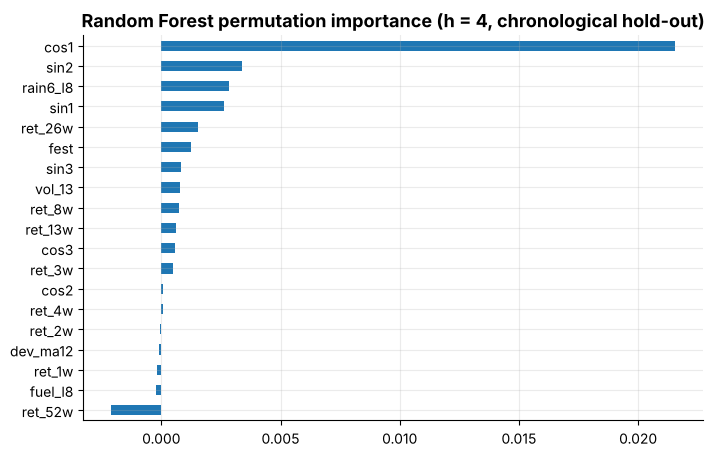

recorded 'Random Forest': 19 origins | MAE overall = 5.72


In [8]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

rf_factory = lambda: RandomForestRegressor(200, min_samples_leaf=5, max_features=0.5, random_state=0, n_jobs=1)
wf_rf = walk_forward_ml(df, rf_factory, horizons=HORIZONS, initial=INITIAL, step=STEP)

X4, y4 = make_ml_table(df, 4); d4 = X4.join(y4.rename("y")).dropna(); k = int(len(d4) * .8)
rf = rf_factory().fit(d4.drop(columns="y").iloc[:k], d4["y"].iloc[:k])
pi = permutation_importance(rf, d4.drop(columns="y").iloc[k:], d4["y"].iloc[k:], n_repeats=10, random_state=0, scoring="neg_mean_absolute_error")
pd.Series(pi.importances_mean, index=X4.columns).sort_values().plot.barh(figsize=(8, 5), title="Random Forest permutation importance (h = 4, chronological hold-out)"); plt.show()

record("Random Forest", wf_rf)

✍️ **Reference answer.** A forest can only output averages of training targets, so on a trending price it would plateau at the training maximum. Returns are stationary and bounded, and the base price carries the trend. In our run the first seasonal harmonic (`cos1`) dominates by a wide margin, followed by `sin2`, the lagged rainfall `rain6_l8` and `sin1`: i.e. the annual cycle and the weather driver, exactly the structure planted in the simulation.

## Step 7 · XGBoost

Record `"XGBoost"` with `XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=0, n_jobs=1)`.

Then **tune honestly**: for h = 4 run a small `GridSearchCV` over `max_depth ∈ {2, 3, 4}` and `learning_rate ∈ {0.03, 0.1}` with `TimeSeriesSplit(n_splits=4, gap=3)`, using only the rows **before the last 52 weeks**. Compare the tuned and default models on the last 52 weeks (price MAE), and say whether tuning was worth it.

<details><summary>💡 Hint 1</summary>

Same pattern as Step 6 with `XGBRegressor`.

</details>

<details><summary>💡 Hint 2</summary>

Tuning recipe: Lesson 6 §6. Training rows: `d.iloc[:-52]`; hold-out: `d.iloc[-52:]`; price forecast = `df['price'].shift(4) * np.exp(pred)`.

</details>

<details><summary>💡 Hint 3</summary>

A tuned model that is *not* better on the hold-out is a perfectly valid, honest finding.

</details>

In [9]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

xgb_factory = lambda: XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=0, n_jobs=1)
wf_xgb = walk_forward_ml(df, xgb_factory, horizons=HORIZONS, initial=INITIAL, step=STEP)

h = 4
X4, y4 = make_ml_table(df, h); d4 = X4.join(y4.rename("y")).dropna(); tr, te = d4.iloc[:-52], d4.iloc[-52:]
grid = GridSearchCV(XGBRegressor(n_estimators=200, subsample=0.8, random_state=0, n_jobs=1),
                    {"max_depth": [2, 3, 4], "learning_rate": [0.03, 0.1]}, cv=TimeSeriesSplit(n_splits=4, gap=h - 1), scoring="neg_mean_absolute_error")
grid.fit(tr.drop(columns="y"), tr["y"])
base = df["price"].shift(h).loc[te.index]; actual = df["price"].loc[te.index]
default = XGBRegressor(random_state=0, n_jobs=1).fit(tr.drop(columns="y"), tr["y"])
print("best params:", grid.best_params_)
print(f"hold-out MAE (last 52 wks, h=4): tuned = {mae(actual, base * np.exp(grid.predict(te.drop(columns='y')))):.2f} | "
      f"default = {mae(actual, base * np.exp(default.predict(te.drop(columns='y')))):.2f} | naive = {mae(actual, base):.2f}")

record("XGBoost", wf_xgb)

best params: {'learning_rate': 0.03, 'max_depth': 2}
hold-out MAE (last 52 wks, h=4): tuned = 5.60 | default = 5.62 | naive = 8.63
recorded 'XGBoost': 19 origins | MAE overall = 5.65


✍️ **Reference answer.** The tuned and default models score within noise of each other: with ~560 rows and strong engineered features, hyper-parameters matter much less than the **target transformation, features and honest evaluation**.

## Step 8 · Model comparison and recommendation

The moment of truth. Everything you recorded is compared **on identical origins, horizons and metrics**.

1. Display `scoreboard(results)`.
2. Plot **MAE by horizon** for all models.
3. Compute each model's **win rate vs naive at h = 8**: the share of forecast origins where its absolute error was smaller than the naive forecast's. A model with lower MAE but a win rate near 50 % wins on a few big moves; a high win rate means *consistent* improvement.
4. Pick the model you would deploy and write a short **recommendation** (template below): best model, evidence, limitations, and the next experiment you'd run.

<details><summary>💡 Hint 1</summary>

Win rate: merge each model's table with the naive table on `(origin, h)` and compare `abs(actual - forecast)`.

</details>

<details><summary>💡 Hint 2</summary>

`results['naive']` must exist for skill and win-rate: it comes from Step 3.

</details>

<details><summary>💡 Hint 3</summary>

Don't over-interpret small differences: with ~19 origins, MAE gaps of a few percent are within noise.

</details>

,MAE h=1,MAE h=4,MAE h=8,MAE all,RMSE all,skill (RMSE)
ARIMAX + Fourier + drivers,3.230,4.951,5.583,4.588,5.985,0.477
Random Forest,3.598,6.320,7.250,5.723,7.332,0.360
XGBoost,4.007,6.019,6.919,5.648,7.365,0.357
Ridge (lag features),3.843,5.811,7.626,5.760,7.465,0.348
Ridge (no drivers),4.115,6.242,7.419,5.925,7.848,0.315
ARIMAX + Fourier,3.947,6.462,6.967,5.792,7.952,0.305
ARIMA,3.381,8.938,13.634,8.651,11.345,0.009
naive,3.447,9.065,13.583,8.699,11.450,0.000
moving average (2),3.658,9.034,13.689,8.794,11.960,-0.045
seasonal naive,18.417,17.687,19.289,18.465,23.258,-1.031


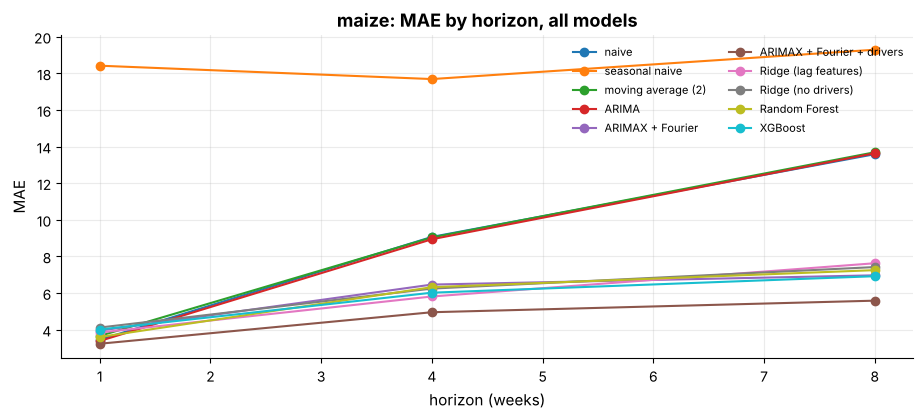

Share of origins (h = 8) where the model's absolute error beat naive:


,win rate
ARIMAX + Fourier + drivers,0.79
Ridge (lag features),0.79
XGBoost,0.74
ARIMAX + Fourier,0.74
Ridge (no drivers),0.68
Random Forest,0.63
ARIMA,0.63
moving average (2),0.58
seasonal naive,0.32


In [10]:
board = scoreboard(results)
display(board)

mae_h = pd.DataFrame({n: {h: mae(w[w.h == h].actual, w[w.h == h].forecast) for h in HORIZONS} for n, w in results.items()})
mae_h.index.name = "horizon (weeks)"
mae_h.plot(marker="o", figsize=(11, 4.2), title=f"{COMMODITY}: MAE by horizon, all models"); plt.ylabel("MAE"); plt.legend(ncol=2, fontsize=8); plt.show()

def win_rate(name, vs="naive", h=8):
    a = results[name].query("h == @h").set_index("origin"); b = results[vs].query("h == @h").set_index("origin")
    return float(((a.actual - a.forecast).abs() < (b.actual - b.forecast).abs()).mean())
wr = pd.Series({n: win_rate(n) for n in results if n != "naive"}).sort_values(ascending=False)
print("Share of origins (h = 8) where the model's absolute error beat naive:"); display(wr.round(2).to_frame("win rate"))

### ✍️ Reference recommendation (maize, simulated market)

**Best model & why:** the **ARIMAX with Fourier seasonality + lagged rain / fuel / festival drivers**. It has the lowest MAE at every horizon (≈ 3.2 / 5.0 / 5.6 at h = 1 / 4 / 8 versus 3.4 / 9.1 / 13.6 for naive) and is among the most consistent (it beats naive at ≈ 80 % of origins at h = 8).

**Evidence:** every model that captures the annual cycle (ARIMAX, Ridge, Random Forest, XGBoost) cuts the 8-week error by about half compared with the baselines; seasonal naive is *worse* than naive because it ignores the upward trend; plain ARIMA and the moving average add nothing over naive. The three ML models are statistically indistinguishable from each other on 19 origins.

**Where it fails / caveats:** at h = 1 nothing clearly beats naive. Forecast errors are largest around drought-driven price spikes. The data are *simulated* with a recipe that is roughly *linear in log prices*: a structure that ARIMAX matches almost perfectly. On real, messier markets with non-linear interactions the ML models (or an ensemble) may catch up or win, so **repeat this on real data before deploying anything**.

**Limitations:** only 19 forecast origins; drivers must be known ≥ 8 weeks ahead (we used lags); no prediction intervals; one market; no retraining schedule.

**Next experiments:** (1) average ARIMAX + XGBoost; (2) prediction intervals from walk-forward residuals; (3) repeat for tomato, onion, rice; (4) a global deep model across commodities.

## 🎓 Submission checklist
- [ ] All eight steps run top-to-bottom without errors.
- [ ] `scoreboard(results)` lists **at least**: naive, seasonal naive, moving average, one ARIMA-family model, Ridge, Random Forest, XGBoost.
- [ ] You wrote the observations/answers in the ✍️ cells.
- [ ] You can explain, for each model, **how leakage was avoided**.
- [ ] You wrote the final recommendation.

### 🚀 Stretch goals
1. Repeat for **tomato, onion and rice**. Does the same model win? Which crop is hardest to forecast and why?
2. Add a **deep-learning** model (`walk_forward_dl`, Lesson 7) and a **3-seed ensemble**.
3. Build a **simple ensemble** (average of ARIMAX + XGBoost forecasts). Ensembles of diverse models often beat every member.
4. Add **prediction intervals** (e.g., from the empirical walk-forward errors) and check their coverage.
5. Then move on to the **capstone project** in `project/`.